# Figure 1: satellite basemap and HRRR-AK comparison

Companion to `figure1.ipynb`, using its **New version — merged 20 m DEM** map.
First draw a standalone satellite map, then a single figure with **A) satellite basemap**
and **B) HRRR-AK data overlay**. The paired panels share the same UTM zone 8N projection,
map extent, axes dimensions, site coordinates, labels, and scale. Panel B retains the
original HRRR temperature, HRRR hillshade, merged 20 m DEM contours, and a larger Alaska inset on B only.

Use the existing **rasterio** environment (see `../../envs/README.md`). New PNG (300 dpi) and PDF exports go to `../files/`. Imagery is from
[Esri World Imagery](https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer),
as in the Canwell map. Satellite acquisition dates differ from the HRRR timestamp.

In [1]:
# Locate figure exports from the repo root, figures/, or figures/notebooks/.
from pathlib import Path
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'envs' / 'rasterio.yml').is_file() and (p / 'figures').is_dir())
FIGURE_FILES = REPO_ROOT / 'figures' / 'files'
FIGURE_FILES.mkdir(parents=True, exist_ok=True)

%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # Register the xarray CRS accessor.
import rasterio
from rasterio.windows import Window, from_bounds
from pyproj import CRS
import geopandas as gpd
from shapely.geometry import Point, box
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource, TwoSlopeNorm
from matplotlib_scalebar.scalebar import ScaleBar
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature

sns.set_theme()
import hashlib
import io
import json
from urllib.parse import urlencode
from urllib.request import Request, urlopen
from PIL import Image


In [2]:
HRRR_PATH = Path('/hdd/snow_hydrology/hrrrak/large_juneau_domain/netcdf/hrrrak_merged_grib_f567_WY2025_utm.nc')
DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')
alaska_shp = '/hdd/snow_hydrology/shape_files/alaska_censusdotgov.shp'
OUTPUT_DIR = FIGURE_FILES
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plot_time = pd.Timestamp('2025-02-20T18:00:00')
show_temperature = True
fontsize = 9
site_marker_size = 85
contour_levels = [250, 500, 750, 1000, 1250, 1500]
temp_norm = TwoSlopeNorm(vmin=-5, vcenter=0, vmax=5)
proj = ccrs.UTM(8)
pc = ccrs.PlateCarree()

# Load only the orography and selected temperature snapshot, then close the file.
with xr.open_dataset(HRRR_PATH) as ds:
    hrrr_crs = ds.rio.crs
    if hrrr_crs is None:
        # Existing convention: this HRRR file was reprojected to EPSG:32608.
        hrrr_crs = CRS.from_epsg(32608)
        print('HRRR CRS absent; assuming EPSG:32608 as in the original figure.')
    if CRS(hrrr_crs) != CRS.from_epsg(32608):
        raise ValueError(f'Unexpected HRRR CRS: {hrrr_crs}')
    terrain = ds['orog'].isel(time=0).load()
    temp = ds['temp'].sel(time=plot_time, method='nearest').load() - 273.15

x, y, z = terrain.x.values, terrain.y.values, terrain.values
actual_time = pd.Timestamp(temp.time.values)
xmin, xmax = np.nanmin(x), np.nanmax(x)
ymin, ymax = np.nanmin(y), np.nanmax(y)
print(f'HRRR CRS: {hrrr_crs}; selected time: {actual_time} UTC')

HRRR CRS absent; assuming EPSG:32608 as in the original figure.
HRRR CRS: EPSG:32608; selected time: 2025-02-20 18:00:00 UTC


## Merged 20 m DEM contours

Read the same native-resolution window, nodata mask, and 250–1500 m contour levels as
the original notebook. Only panel B uses these contours; panel A shows the imagery.

In [3]:
with rasterio.open(DEM_PATH) as src:
    if CRS(src.crs) != CRS.from_epsg(32608):
        raise ValueError(f'Expected WGS 84 / UTM 8N, found {src.crs}')
    if not np.allclose(src.res, (20, 20)):
        raise ValueError(f'Expected a 20 m mosaic, found {src.res}')
    # Pad by one pixel for contours crossing the fixed map boundary.
    requested = from_bounds(xmin - 20, ymin - 20, xmax + 20, ymax + 20, src.transform)
    c0, r0 = int(np.floor(requested.col_off)), int(np.floor(requested.row_off))
    c1, r1 = int(np.ceil(requested.col_off + requested.width)), int(np.ceil(requested.row_off + requested.height))
    window = Window(c0, r0, c1 - c0, r1 - r0).intersection(Window(0, 0, src.width, src.height))
    dem_z = src.read(1, window=window, masked=True).astype('float32')
    transform = src.window_transform(window)
    dem_x = transform.c + (np.arange(dem_z.shape[1]) + 0.5) * transform.a
    dem_y = transform.f + (np.arange(dem_z.shape[0]) + 0.5) * transform.e
    print(f'Contour source: {DEM_PATH.name}; {src.crs}; {src.res} m')
    print(f'Map window: {dem_z.shape}; valid pixels: {dem_z.count():,}/{dem_z.size:,}')
if dem_z.count() == 0:
    raise ValueError('No valid DEM elevations in the map window.')


Contour source: jif_tiles_utm8n_20m.tif; EPSG:32608; (20.0, 20.0) m
Map window: (3569, 2727); valid pixels: 9,728,527/9,732,663


## Satellite image and georeferencing

Request imagery directly in EPSG:32608 for the fixed HRRR map extent. ArcGIS can adjust
the requested bounding box to match the image aspect ratio; use its **returned extent**
for placement, then clip both panels to the original figure extent. Cache the RGB image
and its georeferencing under the system temporary directory so reruns avoid downloads.
Set `BASEMAP_CACHE` to a persistent directory if desired. The image requires internet on
the first run; missing imagery raises an error rather than substituting a blank map.

In [4]:
import os
import tempfile
BASEMAP_CACHE = Path(os.environ.get('BASEMAP_CACHE',
    str(Path(tempfile.gettempdir()) / 'juneau_figure1_basemaps')))
BASEMAP_CACHE.mkdir(parents=True, exist_ok=True)
BASEMAP_SERVICE = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
service = BASEMAP_SERVICE
# Preserve the map aspect ratio in the image request.
image_width = 1400
image_height = min(1800, round(image_width * (ymax-ymin) / (xmax-xmin)))
params = dict(bbox=f'{xmin},{ymin},{xmax},{ymax}', bboxSR=32608, imageSR=32608,
              size=f'{image_width},{image_height}', format='png', transparent='false', f='json')
cache_settings = params if service == 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer' else dict(params, service=service)
key = hashlib.sha256(json.dumps(cache_settings, sort_keys=True).encode()).hexdigest()[:16]
image_file = BASEMAP_CACHE / f'esri_{key}.png'
metadata_file = BASEMAP_CACHE / f'esri_{key}.json'
def fetch(url):
    req = Request(url, headers={'User-Agent': 'JuneauSnowModelingResearch/1.0'})
    import time
    from urllib.error import HTTPError, URLError
    for attempt in range(3):
        try:
            with urlopen(req, timeout=60) as response:
                return response.read()
        except (HTTPError, URLError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2)
if not image_file.exists() or not metadata_file.exists():
    image_info = json.loads(fetch(service + '/export?' + urlencode(params)))
    if 'error' in image_info:
        raise RuntimeError(image_info['error'])
    image_bytes = fetch(image_info['href'])
    Image.open(io.BytesIO(image_bytes)).verify()
    image_file.write_bytes(image_bytes)
    metadata_file.write_text(json.dumps(image_info, indent=2))
image_info = json.loads(metadata_file.read_text())
b = image_info['extent']
basemap_extent = [b['xmin'], b['xmax'], b['ymin'], b['ymax']]
basemap_rgb = np.asarray(Image.open(image_file).convert('RGB'))
print('Basemap:', basemap_rgb.shape, 'extent:', basemap_extent)
ATTRIBUTION = 'Imagery: Esri, Vantor, Earthstar Geographics, and the GIS User Community'


Basemap: (1768, 1400, 3) extent: [497947.25484336715, 554423.3224103136, 6447484.592103873, 6518805.797431274]


## Shared map drawing

Site and landmark positions, text offsets, red domain borders, scale bars, north arrow,
and Alaska inset follow the original figure. HRRR rendering uses the same colour limits,
opacity, timestamp, terrain shading, and unsmoothed 20 m DEM contours. A dedicated colourbar
axis keeps the data panel from shrinking relative to the satellite panel.

In [5]:
def draw_panel(fig, ax, ax_inset=None, cax=None, *, basemap=False):
    """Shared sites and decorations; preserve the original merged DEM overlay."""
    contour_x, contour_y, contour_z = dem_x, dem_y, dem_z
    sites = {
        "PPSA": {"lat": 58.26200, "lon": -134.51700, "elev": 670},
        "TRAM": {"lat": 58.29710, "lon": -134.38600, "elev": 529},
        "HEEN": {"lat": 58.69652, "lon": -134.86448, "elev": 548},
    }

    gdf_sites = gpd.GeoDataFrame(
        {
            "site_id": list(sites.keys()),
            "elev_m": [sites[s]["elev"] for s in sites],
            "geometry": [Point(sites[s]["lon"], sites[s]["lat"]) for s in sites],
        },
        crs="EPSG:4326",
    )

    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(
        z,
        vert_exag=1.5,
        dx=np.nanmedian(np.diff(x)),
        dy=np.nanmedian(np.diff(y)),
    )

    xmin, xmax = np.nanmin(x), np.nanmax(x)
    ymin, ymax = np.nanmin(y), np.nanmax(y)

    domain_poly_utm = gpd.GeoDataFrame(
        geometry=[box(xmin, ymin, xmax, ymax)],
        crs="EPSG:32608",
    ).to_crs("EPSG:4326")

    if basemap:
        ax.imshow(basemap_rgb, extent=basemap_extent, origin='upper',
                  transform=proj, interpolation='antialiased', zorder=1)
    else:
        ax.pcolormesh(
            x, y, hillshade,
            cmap="Greys",
            shading="auto",
            transform=proj,
            alpha=0.95,
            zorder=1,
        )

        if show_temperature:
            im = ax.pcolormesh(
                x, y, temp.values,
                cmap="coolwarm",
                shading="auto",
                norm=temp_norm,
                transform=proj,
                alpha=0.62,
                zorder=2,
            )

            cbar = fig.colorbar(im, cax=cax)
            cbar.set_label("HRRR-AK air temperature (°C)", fontsize=fontsize)
            cbar.ax.tick_params(labelsize=fontsize - 1)
        else:
            cax.set_visible(False)

        contours = ax.contour(
            contour_x, contour_y, contour_z,
            levels=contour_levels,
            colors="black",
            linewidths=0.45,
            alpha=0.55,
            transform=proj,
            zorder=3,
        )

        ax.clabel(
            contours,
            inline=True,
            fontsize=7,
            fmt="%d m",
        )


    ax.set_extent([xmin, xmax, ymin, ymax], crs=proj)

    if not basemap:
        ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=4)
        ax.add_feature(cfeature.LAKES, linewidth=0.4, alpha=0.4, zorder=4)
        ax.add_feature(cfeature.RIVERS, linewidth=0.3, alpha=0.35, zorder=4)


    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.35,
        color="gray",
        alpha=0.45,
        linestyle="--",
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}

    label_offsets = {
        "PPSA": (-0.035, -0.035),
        "TRAM": (0.040, 0.030),
        "HEEN": (0.035, 0.035),
    }

    for _, row in gdf_sites.iterrows():
        lon = row.geometry.x
        lat = row.geometry.y
        site = row["site_id"]

        ax.scatter(
            lon, lat,
            s=site_marker_size,
            marker="o",
            facecolor="red",
            edgecolor="black",
            linewidth=1.0,
            transform=pc,
            zorder=10,
        )

        dx, dy = label_offsets.get(site, (0.02, 0.02))

        txt = ax.text(
            lon + dx,
            lat + dy,
            f"{site}\n{int(row['elev_m'])} m",
            fontsize=8.5,
            fontweight="bold",
            ha="center",
            va="center",
            color="white",
            transform=pc,
            zorder=11,
        )

        txt.set_path_effects([
            pe.withStroke(linewidth=2.3, foreground="black")
        ])

    landmarks = [
        {
            "name": "JNU Airport",
            "lon": -134.576,
            "lat": 58.354,
            "marker": "s",
            "dx": -0.055,
            "dy": 0.02,
            "ha": "left",
        },
        {
            "name": "Douglas Island",
            "lon": -134.575,
            "lat": 58.275,
            "marker": "s",
            "dx": 0.06,
            "dy": 0.02,
            "ha": "right",
        },
    ]

    for lm in landmarks:
        ax.scatter(
            lm["lon"], lm["lat"],
            transform=pc,
            s=35,
            marker=lm["marker"],
            facecolor="black",
            edgecolor="white",
            linewidth=0.5,
            zorder=9,
        )

        txt = ax.text(
            lm["lon"] + lm["dx"],
            lm["lat"] + lm["dy"],
            lm["name"],
            fontsize=7,
            color="white",
            ha=lm["ha"],
            va="center",
            transform=pc,
            zorder=10,
        )

        txt.set_path_effects([
            pe.withStroke(linewidth=2.0, foreground="black")
        ])

    scalebar = ScaleBar(
        dx=1,
        units="m",
        location="lower left",
        length_fraction=0.22,
        box_alpha=0.85,
        font_properties={"size": 8},
    )

    ax.add_artist(scalebar)

    ax.annotate(
        "N",
        xy=(0.03, 0.185),
        xytext=(0.03, 0.105),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        arrowprops=dict(
            facecolor="black",
            edgecolor="black",
            width=2,
            headwidth=7,
            headlength=8,
        ),
        zorder=20,
    )

    if show_temperature and not basemap:
        timestamp_str = actual_time.strftime("%Y-%m-%d %H:%M UTC")

        ax.text(
            0.98, 0.98,
            timestamp_str,
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8.5,
            fontweight="bold",
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                alpha=0.88,
                boxstyle="round,pad=0.25",
            ),
            zorder=20,
        )

    if ax_inset is not None:
        ak = gpd.read_file(alaska_shp).to_crs(ax_inset.projection.proj4_init)

        ak.plot(
            ax=ax_inset,
            facecolor="0.92",
            edgecolor="black",
            linewidth=0.45,
            zorder=1,
        )

        domain_poly_ak = domain_poly_utm.to_crs(ax_inset.projection.proj4_init)
        domain_poly_ak.boundary.plot(
            ax=ax_inset,
            edgecolor="red",
            linewidth=1.4,
            zorder=5,
        )

        ax_inset.set_extent([-180, -128, 50, 73], crs=pc)
        ax_inset.set_axis_off()


    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("red")
        spine.set_linewidth(2.5)

    return gl


In [6]:
def alaska_inset(ax):
    return ax.inset_axes([0.49, 0.55, 0.72, 0.44],
        projection=ccrs.AlbersEqualArea(central_longitude=-154,
            central_latitude=50, standard_parallels=(55, 65)))

def export_figure(fig, stem):
    for extension in ('png', 'pdf'):
        path = OUTPUT_DIR / f'{stem}.{extension}'
        fig.savefig(path, dpi=300, bbox_inches='tight')
        print('Saved:', path)


## Standalone satellite map

Sites and regional context, without HRRR temperature, hillshade, or DEM contours.

Saved: /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_basemap.png


Saved: /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_basemap.pdf


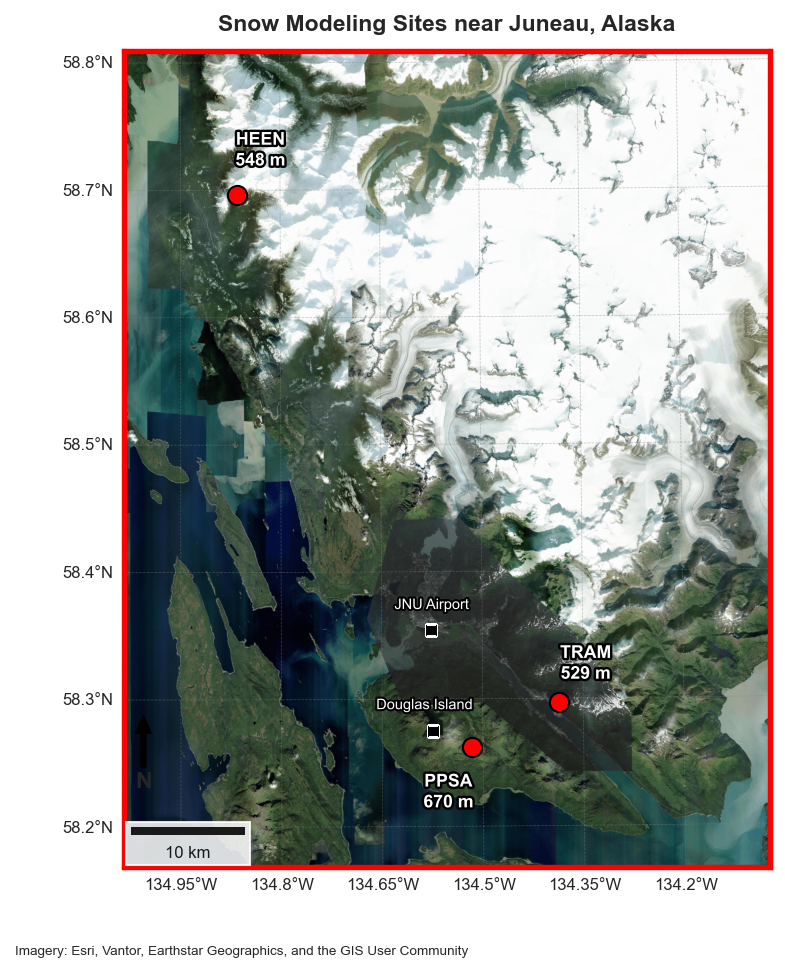

In [7]:
fig = plt.figure(figsize=(7.2, 6.8), dpi=150)
ax = fig.add_axes([0.10, 0.12, 0.80, 0.80], projection=proj)
draw_panel(fig, ax, basemap=True)
ax.set_title('Snow Modeling Sites near Juneau, Alaska', fontsize=11, fontweight='bold', pad=10)
fig.text(0.10, 0.035, ATTRIBUTION, fontsize=6.5)
export_figure(fig, 'figure1_basemap')
plt.show()
plt.close(fig)


## A) Satellite basemap · B) HRRR-AK data overlay

The two maps use identical map limits and equal-size axes. The right panel is the original
merged 20 m DEM version; the left provides satellite context at the same scale.
The check below verifies both geographic extent and physical plotting scale after layout.

Verified: equal map scales and extents; frame gap = 0.35 inches.


Saved: /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_basemap_comparison.png


Saved: /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_basemap_comparison.pdf


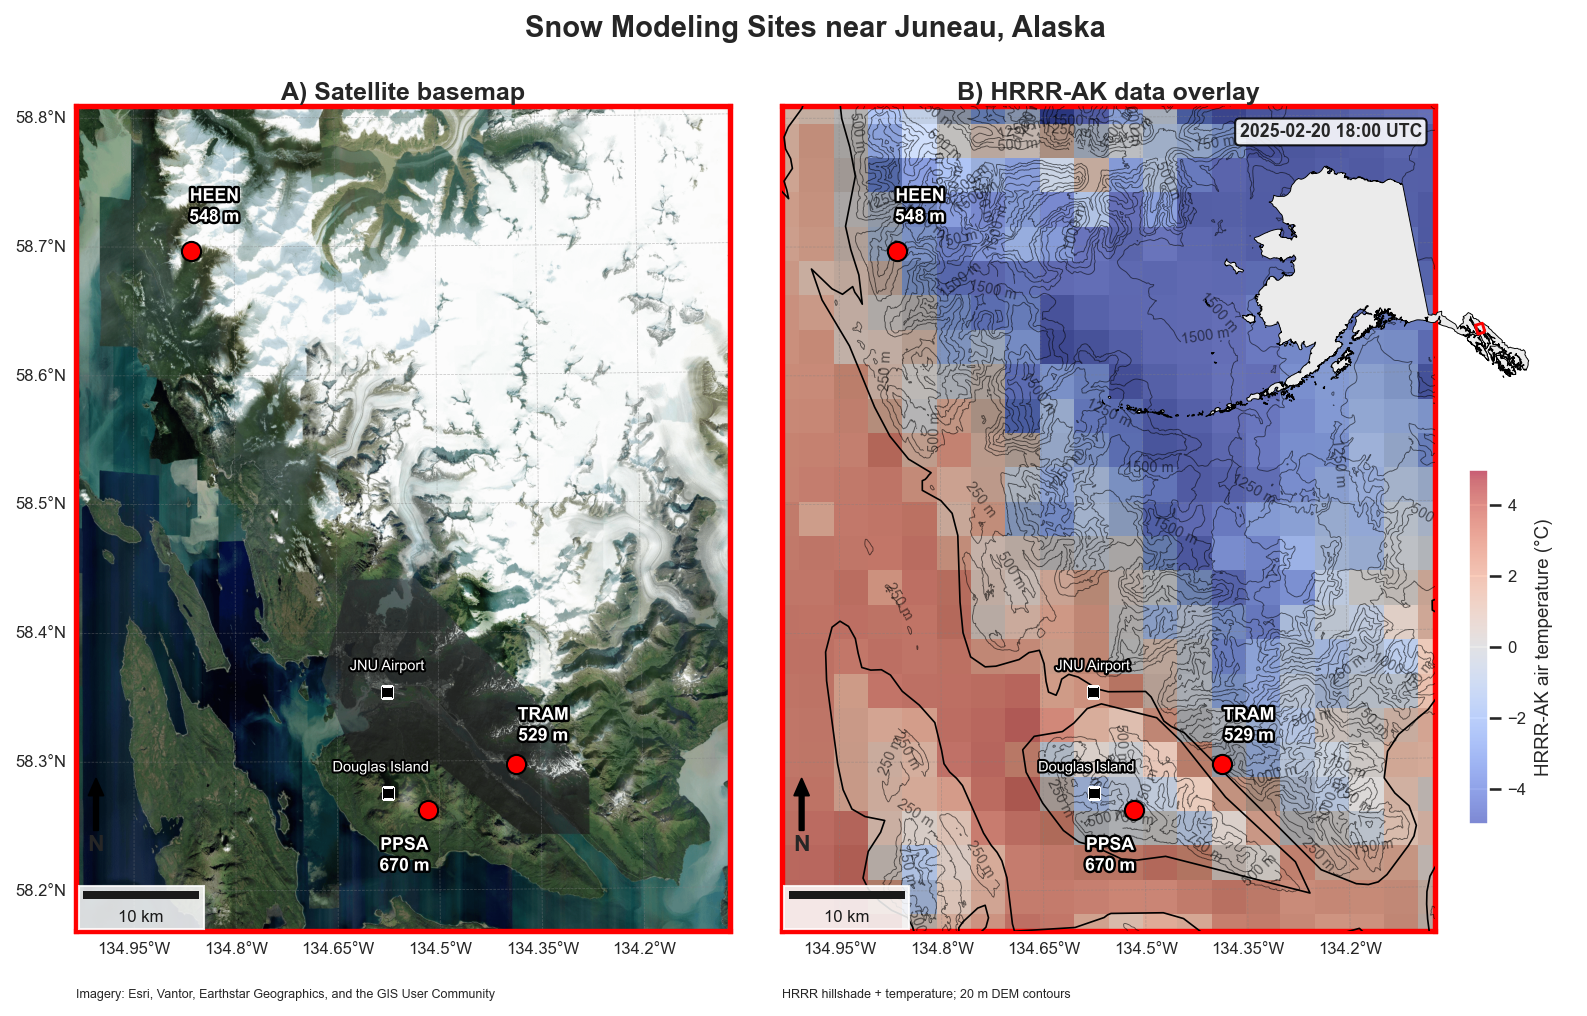

In [8]:
# Define map sizes in inches so Cartopy's fixed aspect cannot add a wide gutter.
map_height = 5.5
map_width = map_height * (xmax-xmin) / (ymax-ymin)
panel_gap = 0.35  # inches between the red map frames
left, bottom = 0.65, 0.72
right_margin, top_margin = 1.45, 0.68
figure_width = left + 2*map_width + panel_gap + right_margin
figure_height = bottom + map_height + top_margin
fig = plt.figure(figsize=(figure_width, figure_height), dpi=150)
def map_rect(x_left):
    return [x_left/figure_width, bottom/figure_height,
            map_width/figure_width, map_height/figure_height]
ax_a = fig.add_axes(map_rect(left), projection=proj)
ax_b = fig.add_axes(map_rect(left + map_width + panel_gap), projection=proj)
# The colourbar sits below the larger inset, outside the right map frame.
cax = fig.add_axes([(left+2*map_width+panel_gap+0.22)/figure_width,
                    (bottom+0.13*map_height)/figure_height,
                    0.13/figure_width, 0.43*map_height/figure_height])
draw_panel(fig, ax_a, basemap=True)
gridlines_b = draw_panel(fig, ax_b, alaska_inset(ax_b), cax=cax, basemap=False)
# Shared latitude labels avoid clutter in the narrow gutter.
gridlines_b.left_labels = False
ax_a.set_title('A) Satellite basemap', fontsize=12, fontweight='bold', y=1.0, pad=3)
ax_b.set_title('B) HRRR-AK data overlay', fontsize=12, fontweight='bold', y=1.0, pad=3)
fig.suptitle('Snow Modeling Sites near Juneau, Alaska', fontsize=14, fontweight='bold', y=0.99)
fig.text(left/figure_width, 0.04, ATTRIBUTION, fontsize=6)
fig.text((left+map_width+panel_gap)/figure_width, 0.04,
         'HRRR hillshade + temperature; 20 m DEM contours', fontsize=6)
fig.canvas.draw()
np.testing.assert_allclose(ax_a.get_extent(proj), ax_b.get_extent(proj), atol=1e-5)
np.testing.assert_allclose(ax_a.get_window_extent().size, ax_b.get_window_extent().size,
                           rtol=1e-8, atol=1e-5)
actual_gap = (ax_b.get_window_extent().x0 - ax_a.get_window_extent().x1) / fig.dpi
np.testing.assert_allclose(actual_gap, panel_gap, atol=1e-4)
print(f'Verified: equal map scales and extents; frame gap = {actual_gap:.2f} inches.')
export_figure(fig, 'figure1_basemap_comparison')
plt.show()
plt.close(fig)


## Choosing imagery later

The current World Imagery layer is a mosaic of different source images; it is not a
single-date photograph. This export endpoint does not provide an acquisition-date selector.
Dark patches may be terrain shadows or differences between source images, as well as clouds.

For an alternate view, browse [Esri World Imagery Wayback](https://livingatlas.arcgis.com/wayback/)
over Juneau and compare releases with **local changes**. A Wayback release date is the date
that mosaic was published, **not** the acquisition date of all its imagery. Click the map
in the app to inspect source capture date, provider, and resolution. An older release may
look clearer locally; it is not guaranteed to be cloud- or shadow-free.

Once a preferred release is chosen, the image-loading cell can be adapted to that release's
WMTS/tile service, or to a selected georeferenced raster. A Wayback WMTS URL is not a drop-in
replacement for the current `/export` MapServer URL. `BASEMAP_SERVICE` above supports other
export-capable map services; both the imagery and attribution should be updated together.
Changing PNG export DPI alone does not improve the source imagery or remove shadows.

References: [Esri Wayback guide](https://www.esri.com/arcgis-blog/products/arcgis-living-atlas/mapping/use-world-imagery-wayback),
[Esri source-image metadata guide](https://www.esri.com/arcgis-blog/products/arcgis-living-atlas/imagery/create-more-with-world-imagery-wayback).
